# IPERLITE based wildfire analysis

As a follow-up to the initial data loading workflow presented in [load-iperlite-stac.ipynb](../../20_data-discovery/iperlite/load-iperlite-stac.ipynb), in this notebook, we want to showcase how users can use several openEO processes to perform analysis on the IPERLITE data.

In this example, we load IPERLITE L1C data from the Terrascope STAC Catalogue over the Sierra Calderona Natural Park (Spain), calculate five spectral indices, and compare a pre-fire scene (27 July 2026) with a post-fire scene (29 August 2026) using openEO processes.

On the evening of 20 August 2026, a lightning strike started a wildfire in the municipality of Segorbe (Castellón) that spread into Gátova (Valencia) and burned about 630 ha of the Sierra Calderona Natural Park before being contained on 22 August. IPERLITE acquired the area on 27 July 2026 (before the fire) and on 29 August 2026 (one week after containment), which makes it a suitable test case for a simple pre/post spectral index comparison.

> **Note on the processing level:** this example uses the IPERLITE **L1C** (top-of-atmosphere reflectance) collection because, at the time of writing, the Sierra Calderona acquisitions are not yet available as L2A (top-of-canopy reflectance) products. The notebook is meant to illustrate the workflow; for a quantitative analysis the L2A collection is preferred and can be used by switching the collection URL to `terrascope-iperlite-l2a-cog-v1` and the band names from `RTOA*` to `RTOC*`. See [iperlite-rice-phenology.ipynb](../iperlite-rice-phenology/iperlite-rice-phenology.ipynb) for the same workflow applied to L2A data.

For more information on the IPERLITE data and the available spectral indices, please refer to the [IPERLITE documentation](https://eo.belspo.be/nl/satellites-and-sensors/iperlite).

In [2]:
import openeo

connection = openeo.connect("openeo.terrascope.be").authenticate_oidc()

Authenticated using refresh token.


Let us start by defining the area of interest (AOI), time range, bands for our analysis and the URL of the Terrascope STAC Catalogue.

In [3]:
IPERLITE_L1C = "https://stac.terrascope.be/collections/terrascope-iperlite-l1c-cog-v1"

# AOI over the Sierra Calderona burn scar between Segorbe (Castellón) and Gátova (Valencia),
# covered by the 27 July (pre-fire) and 29 August (post-fire) IPERLITE scenes.
aoi = {
    "type": "Polygon",
    "coordinates": [[
        [-0.44, 39.74],
        [-0.44, 39.86],
        [-0.60, 39.86],
        [-0.60, 39.74],
        [-0.44, 39.74],
    ]],
}

pre_period = ["2026-07-27", "2026-07-28"]
post_period = ["2026-08-29", "2026-08-30"]

# RTOA bands nearest to 531, 550, 570, 665, 680, 705, 750, 783, and 842 nm.
bands = ["RTOA18", "RTOA23", "RTOA33", "RTOA52", "RTOA58", "RTOA66", "RTOA84", "RTOA101", "RTOA122"]
print(f"Pre-fire window: {pre_period}; post-fire window: {post_period}")

Pre-fire window: ['2026-07-27', '2026-07-28']; post-fire window: ['2026-08-29', '2026-08-30']


Load the selected IPERLITE data using `load_stac`. The subset is loaded for the AOI and date range instead of downloading complete scenes.

In [4]:
cube = connection.load_stac(
    url=IPERLITE_L1C,
    spatial_extent=aoi,
    temporal_extent=["2026-07-27", "2026-08-30"],
    bands=bands,
)

Since the interest is in understanding the vegetation dynamics and stress responses over a region after a wildfire, let us calculate several spectral indices that highlight different aspects of plant health and burned areas. The indices used here were selected from a random literature review based on their relevance to post-wildfire vegetation monitoring. These indices compare complementary vegetation signals using IPERLITE's VNIR bands, including broad greenness, chlorophyll-sensitive red-edge response, short-term photosynthetic stress, chlorophyll absorption depth, and a red/NIR burned-area signal.

- Normalised Difference Vegetation Index (**NDVI**) = (R842 - R665) / (R842 + R665): The NDVI gives an idea of the vegetation greenness and overall health ([Tucker, 1979](https://doi.org/10.1016/0034-4257(79)90013-0)).
- Chlorophyll Index Red Edge (**CIre**) = R783 / R705 - 1: The CIre provides a measure of chlorophyll content in vegetation([Gitelson et al., 2003](https://doi.org/10.1078/0176-1617-00887)).
- Photochemical Reflectance Index (**PRI**) = (R531 - R570) / (R531 + R570): The PRI is a signal associated with photosynthetic light-use efficiency and xanthophyll-cycle activity; it may respond to physiological stress, but is also sensitive to illumination and canopy conditions ([Gamon et al., 1992](https://doi.org/10.1016/0034-4257(92)90059-S)).
- Chlorophyll Absorption Depth at 680 nm (**CAD680**) = 1 - R680 / Rcontinuum: With the CAD680, we estimate the depth of the chlorophyll absorption feature near 680 nm relative to a local spectral baseline. Here, Rcontinuum is a simplified continuum-depth calculation used in this example. [Yang et al. (2006)](https://doi.org/10.1631/jzus.2006.A2002) 
- Burned Area Index (**BAI**) = 1 / ((0.1 - R665)^2 + (0.06 - R842)^2): The BAI measures inverse spectral distance from a reference red/NIR reflectance point associated with burned surfaces ([Chuvieco et al., 2002](https://doi.org/10.1080/01431160210153129)). 

In [6]:
# fetch the individual spectral bands from the cube
r531 = cube.band("RTOA18")
r550 = cube.band("RTOA23")
r570 = cube.band("RTOA33")
r665 = cube.band("RTOA52")
r680 = cube.band("RTOA58")
r705 = cube.band("RTOA66")
r750 = cube.band("RTOA84")
r783 = cube.band("RTOA101")
r842 = cube.band("RTOA122")

In [7]:
# Calculate spectral indices 
ndvi = ((r842 - r665) / (r842 + r665)).add_dimension(
    name="bands", label="NDVI", type="bands"
)
cire = (r783 / r705 - 1).add_dimension(
    name="bands", label="CIre", type="bands"
)
pri = ((r531 - r570) / (r531 + r570)).add_dimension(
    name="bands", label="PRI", type="bands"
)

continuum_680 = r550 + (r750 - r550) * (130 / 200)
cad680 = (1 - r680 / continuum_680).add_dimension(
    name="bands", label="CAD680", type="bands"
)

# FOR BAI: Use 1.0 for reflectance in 0-1 units, or 0.0001 for raw values scaled by 10000.
BAI_REFLECTANCE_SCALE = 1.0
red_reflectance = r665 * BAI_REFLECTANCE_SCALE
nir_reflectance = r842 * BAI_REFLECTANCE_SCALE
bai_distance_squared = (
    (0.1 - red_reflectance) * (0.1 - red_reflectance)
    + (0.06 - nir_reflectance) * (0.06 - nir_reflectance)
)
bai = (1 / bai_distance_squared).add_dimension(
    name="bands", label="BAI", type="bands"
)

BAI's reference values are used to interpret the Burned Area Index (BAI) calculated above. The reason for using these reference values is to provide a consistent basis for comparison across different datasets and reflectance scales.

In [8]:
# combine all spectral indices into a single cube
indices = (
    ndvi.merge_cubes(cire)
    .merge_cubes(pri)
    .merge_cubes(cad680)
    .merge_cubes(bai)
)
indices

Now to compare pre- and post-period composites, we need to create separate composites for each period using the `filter_temporal` and `reduce_dimension`. 

The filter_temporal process selects the relevant time window for the pre- and post-periods, and the reduce_dimension process computes a per-pixel median over the selected acquisitions. Here each window contains a single IPERLITE scene, so the median simply collapses the time dimension; widening `post_period` would turn it into a true multi-scene composite. 

In the cell below, we then perform the subtraction, with the result representing the change in each index.

In [7]:
pre_indices = indices.filter_temporal(pre_period).reduce_dimension(
    dimension="t", reducer="median"
)
post_indices = indices.filter_temporal(post_period).reduce_dimension(
    dimension="t", reducer="median"
)

change = (post_indices - pre_indices).rename_labels(
    dimension="bands",
    target=["dNDVI", "dCIre", "dPRI", "dCAD680", "dBAI"],
)
change

The `d` prefix means post minus pre. 

Now, we can submit the above datacube with 5 bands with difference between the post- and pre-period composites. In the cell below we also specify the output format to NetCDF, user can select the desired output format based on their preference.

In [8]:
change.execute_batch(
    title="IPERLITE spectral index change",
    outputfile="change_detection_sierra_calderona.nc",
)

0:00:00 Job 'j-26111008212247a9bd170d78e6fccf68': send 'start'
0:00:15 Job 'j-26111008212247a9bd170d78e6fccf68': created (progress 0%)
0:00:20 Job 'j-26111008212247a9bd170d78e6fccf68': queued (progress 0%)
0:00:26 Job 'j-26111008212247a9bd170d78e6fccf68': queued (progress 0%)
0:00:34 Job 'j-26111008212247a9bd170d78e6fccf68': queued (progress 0%)
0:00:44 Job 'j-26111008212247a9bd170d78e6fccf68': queued (progress 0%)
0:00:57 Job 'j-26111008212247a9bd170d78e6fccf68': running (progress 6.7%)
0:01:12 Job 'j-26111008212247a9bd170d78e6fccf68': running (progress 8.9%)
0:01:31 Job 'j-26111008212247a9bd170d78e6fccf68': running (progress 11.4%)
0:01:55 Job 'j-26111008212247a9bd170d78e6fccf68': running (progress 14.5%)
0:02:25 Job 'j-26111008212247a9bd170d78e6fccf68': finished (progress 100%)


<BatchJob job_id='j-26111008212247a9bd170d78e6fccf68'>

In [9]:
import xarray as xr

change_ds = xr.open_dataset("change_detection_sierra_calderona.nc")
change_ds

<xarray.Dataset> Size: 10MB
Dimensions:  (y: 686, x: 705)
Coordinates:
  * y        (y) float64 5kB 4.415e+06 4.415e+06 ... 4.402e+06 4.402e+06
  * x        (x) float64 6kB 7.053e+05 7.053e+05 ... 7.194e+05 7.194e+05
Data variables:
    crs      |S1 1B ...
    dNDVI    (y, x) float32 2MB ...
    dCIre    (y, x) float32 2MB ...
    dPRI     (y, x) float32 2MB ...
    dCAD680  (y, x) float32 2MB ...
    dBAI     (y, x) float32 2MB ...
Attributes:
    Conventions:  CF-1.9
    institution:  VITO Terrascope openEO API - 0.74.0a4.dev20261026+283
    description:  
    title:

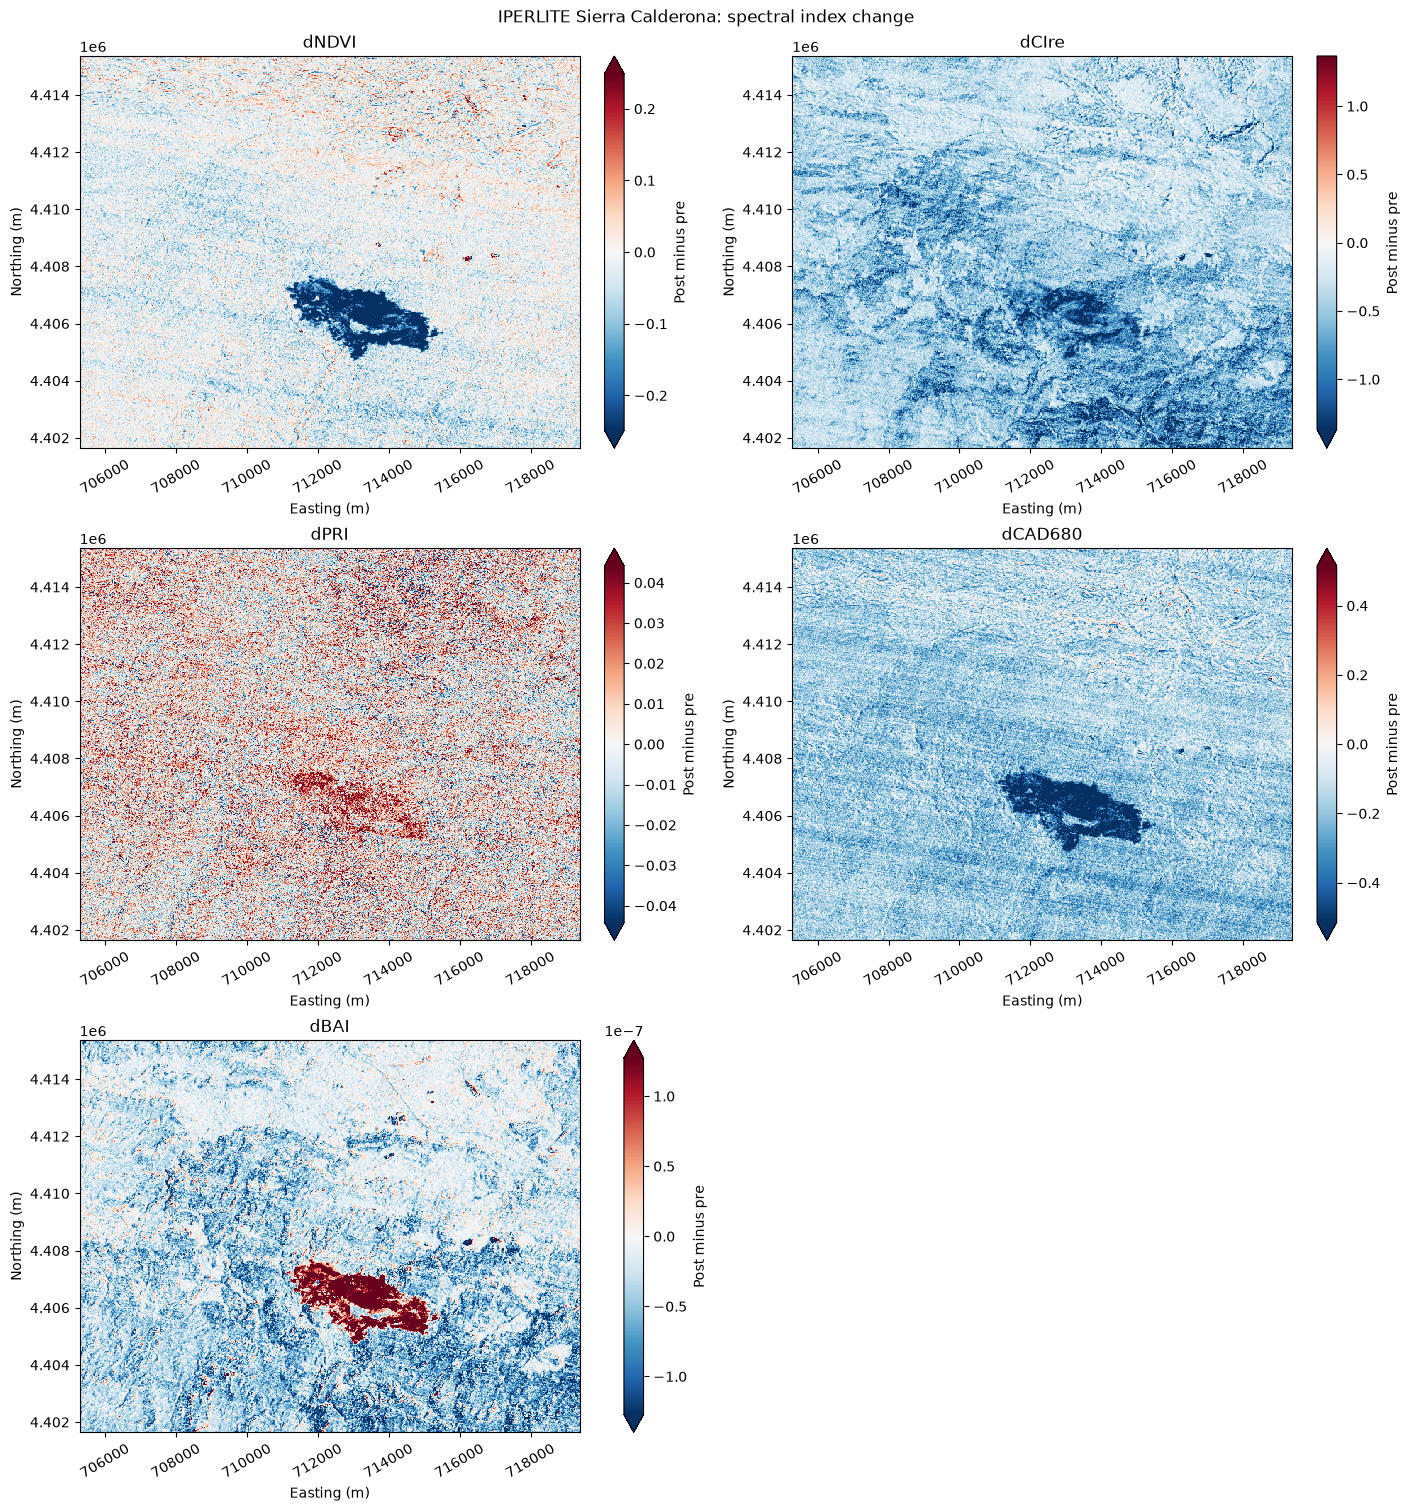

In [10]:
import matplotlib.pyplot as plt

index_names = ["dNDVI", "dCIre", "dPRI", "dCAD680", "dBAI"]
fig, axes = plt.subplots(3, 2, figsize=(14, 15), constrained_layout=True)
axes.flat[-1].set_visible(False)

for ax, name in zip(axes.flat, index_names):
    change_ds[name].plot(ax=ax, cmap="RdBu_r", center=0, robust=True, cbar_kwargs={"label": "Post minus pre"})
    ax.set_title(name)
    ax.set_xlabel("Easting (m)")
    ax.set_ylabel("Northing (m)")
    ax.tick_params(axis="x", labelrotation=30)

fig.suptitle("IPERLITE Sierra Calderona: spectral index change")
plt.show()

The reporting from EMS confirms the result: https://mapping.emergency.copernicus.eu/activations/EMSR925/reporting/.


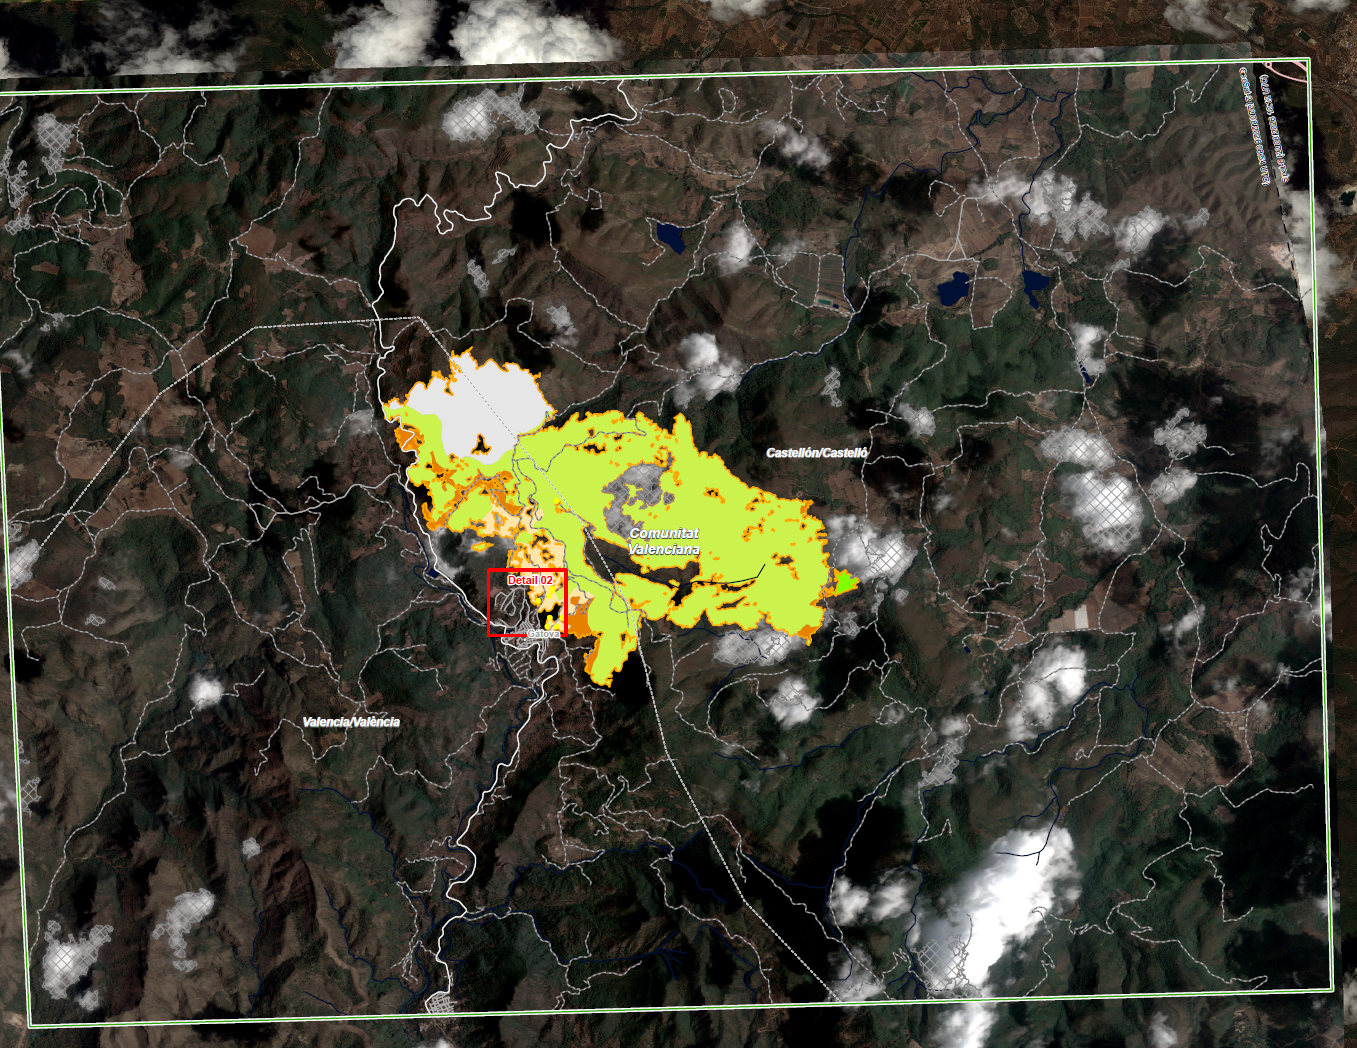